In [1]:
!pip install -q openai-whisper peft sentencepiece
!pip uninstall -y -q torchao

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 3.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, glob, json, math, random, threading
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa, torch, torch.nn as nn, torch.nn.functional as F, whisper
from tqdm.auto import tqdm
from scipy.stats import pearsonr
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.svm import SVR
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import mean_squared_error
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup,
                          WhisperFeatureExtractor, WhisperModel, AutoFeatureExtractor, WavLMModel)
from peft import LoraConfig, inject_adapter_in_model

DATA = "/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/"
devs = [f"cuda:{i}" for i in range(torch.cuda.device_count())] or ["cpu"]

def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))

def find(name):
    for folder in ["."] + glob.glob("/kaggle/input/*") + glob.glob("/kaggle/input/*/*") + glob.glob("/kaggle/input/*/*/*"):
        if os.path.exists(os.path.join(folder, name)):
            return os.path.join(folder, name)
    return None

def on_all_gpus(func, items, load_models):
    models = [load_models(d) for d in devs]
    def run(part, dev, m):
        if dev != "cpu":
            torch.cuda.set_device(dev)
        return func(part, dev, m)
    with ThreadPoolExecutor(max_workers=len(devs)) as pool:
        jobs = [pool.submit(run, items[i::len(devs)], d, m) for i, (d, m) in enumerate(zip(devs, models))]
        results = [j.result() for j in jobs]
    merged = [None] * len(items)
    for i, r in enumerate(results):
        merged[i::len(devs)] = r
    return merged

def distribute(jobs, func):
    # runs func(job, device) for every job; every GPU does its share of the jobs one after the other. Returns {job key: result}
    def run(job_list, dev):
        if dev != "cpu":
            torch.cuda.set_device(dev)
        return {job[0]: func(job, dev) for job in job_list}
    with ThreadPoolExecutor(max_workers=len(devs)) as pool:
        futures = [pool.submit(run, jobs[d::len(devs)], dev) for d, dev in enumerate(devs)]
        results = {}
        for f in futures:
            results.update(f.result())
    return results

load_lock = threading.Lock()           # models of the fine-tuning jobs are loaded one at a time

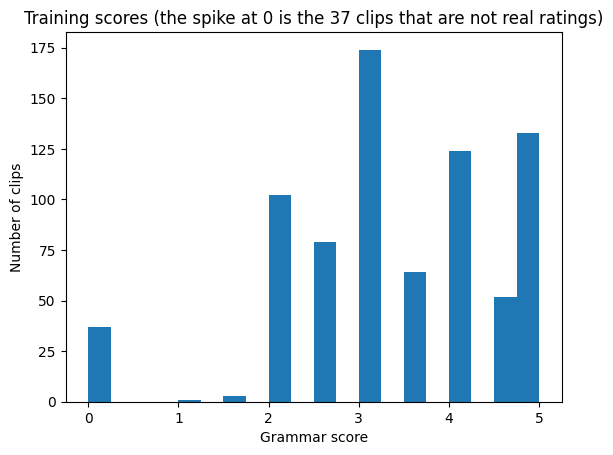

In [3]:
train = pd.read_csv(DATA + "train.csv")
test = pd.read_csv(DATA + "test.csv")
train["path"] = DATA + "train/" + train["filename"]
test["path"] = DATA + "test/" + test["filename"]
data = pd.concat([train, test], ignore_index=True)         # train clips first, then test clips, in every array of the notebook
y = train["label"].values.astype(float)
n_train = len(train)
durations = np.array([librosa.get_duration(path=p) for p in data["path"]])

plt.hist(y, bins=20)
plt.xlabel("Grammar score"); plt.ylabel("Number of clips"); plt.title("Training scores (the spike at 0 is the 37 clips that are not real ratings)")
plt.show()

short = durations < 52                    
zero = y == 0                             
W = np.ones(n_train)
for batch in (True, False):
    in_train = (short[:n_train] == batch) & ~zero
    W[in_train] = (short[n_train:] == batch).mean() / (short[:n_train][~zero] == batch).mean()
W[zero] = 0
W = W / W[W > 0].mean()                  
keep = W > 0                             

def wrmse(a, b):
    
    return float(np.sqrt(np.sum(W * (np.asarray(a) - np.asarray(b)) ** 2) / W.sum()))

def fit_weighted(model, X, y_fit, w):
    
    model.fit(X, y_fit, **{model.steps[-1][0] + "__sample_weight": w})
    return model

folds = list(KFold(5, shuffle=True, random_state=0).split(np.arange(n_train)))      # one fixed split for all models

In [4]:
PROMPT = "Umm, let me think like, hmm... Okay, here's what I'm, like, thinking. I I mean, we went, we go there."

def load_whisper(dev):
    return whisper.load_model("small", device=dev)

def transcribe(paths, dev, asr):
    out = []
    for path in tqdm(paths, desc=dev):
        audio = librosa.load(path, sr=16000)[0]
        r = asr.transcribe(audio, language="en", condition_on_previous_text=False, initial_prompt=PROMPT, fp16=(dev != "cpu"))
        out.append({"text": r["text"].strip()})
    return out

path = find("transcripts.json")
if path:
    transcripts = json.load(open(path))
else:
    transcripts = on_all_gpus(transcribe, list(data["path"]), load_whisper)
    json.dump(transcripts, open("transcripts.json", "w"))
texts = [t["text"] if t["text"] else "." for t in transcripts]

In [ ]:
def make_encoder_loader(name, layers):
    def loader(dev):
        half = "large" in name and dev != "cpu"
        fe = WhisperFeatureExtractor.from_pretrained(name)
        model = WhisperModel.from_pretrained(name, torch_dtype=torch.float16 if half else torch.float32)
        return fe, model.encoder.to(dev).eval(), layers, half
    return loader

def whisper_embed(paths, dev, models):
    fe, encoder, layers, half = models
    out = []
    for path in tqdm(paths, desc=dev):
        audio = librosa.load(path, sr=16000)[0]
        vecs, weights = [], []
        for start in range(0, len(audio), 30 * 16000):        # Whisper takes 30 seconds at a time
            chunk = audio[start:start + 30 * 16000]
            if start > 0 and len(chunk) < 2 * 16000:
                continue
            feats = fe(chunk, sampling_rate=16000, return_tensors="pt").input_features.to(dev)
            if half:
                feats = feats.half()
            with torch.no_grad():
                hidden = encoder(feats, output_hidden_states=True).hidden_states
            n_frames = int(np.ceil(len(chunk) / 320))          # 50 frames per second of real audio
            vecs.append(torch.stack([hidden[l][0, :n_frames].float().mean(0) for l in layers]).mean(0).cpu().numpy())
            weights.append(n_frames)
        out.append(np.average(vecs, axis=0, weights=weights))
    return out

def load_wavlm(dev):
    return AutoFeatureExtractor.from_pretrained("microsoft/wavlm-base-plus"), WavLMModel.from_pretrained("microsoft/wavlm-base-plus").to(dev).eval()

def wavlm_embed(paths, dev, models):
    fe, wavlm = models
    out = []
    for path in tqdm(paths, desc=dev):
        x = fe(librosa.load(path, sr=16000)[0], sampling_rate=16000, return_tensors="pt").input_values.to(dev)
        with torch.no_grad():
            hidden = wavlm(x, output_hidden_states=True).hidden_states
        h = torch.stack([hidden[l][0] for l in range(7, 11)]).mean(0)
        out.append(torch.cat([h.mean(0), h.std(0)]).cpu().numpy())
    return out

def embeddings(file, extract, loader):
    path = find(file)
    if path:
        return np.load(path)
    emb = np.array(on_all_gpus(extract, list(data["path"]), loader))
    np.save(file, emb)
    return emb

whisper_emb = embeddings("whisper_emb.npy", whisper_embed, make_encoder_loader("openai/whisper-small", range(8, 13)))
wavlm_emb = embeddings("wavlm_emb.npy", wavlm_embed, load_wavlm)
whisper_large_emb = embeddings("whisper_large_emb.npy", whisper_embed, make_encoder_loader("openai/whisper-large-v3", range(20, 33)))
assert (whisper_emb.shape[1], wavlm_emb.shape[1], whisper_large_emb.shape[1]) == (768, 1536, 1280), "wrong embedding file"



In [ ]:
def ridge_model():
    return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(1, 5, 16)))

def svr_model():
    return make_pipeline(StandardScaler(), PCA(64), SVR(C=2, epsilon=0.2))

def tfidf_model():
    return make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), RidgeCV(alphas=np.logspace(-1, 2, 12)))

base_models = {                       # name: (features, model)
    "whisper SVR": (whisper_emb, svr_model),
    "wavlm Ridge": (wavlm_emb, ridge_model),
    "whisper large SVR": (whisper_large_emb, svr_model),
    "TF-IDF Ridge": (np.array(texts, dtype=object), tfidf_model),
}

oof, test_pred, train_pred = {}, {}, {}      # out-of-fold, test and in-sample predictions of every model
for name, (X, make_model) in base_models.items():
    X_train, X_test = X[:n_train], X[n_train:]
    oof_all, test_sum = np.zeros((3, n_train)), np.zeros(len(X_test))
    for repeat in range(3):
        for tr, va in KFold(5, shuffle=True, random_state=repeat).split(X_train):
            m = fit_weighted(make_model(), X_train[tr], y[tr], W[tr])
            oof_all[repeat, va] = m.predict(X_train[va])
            test_sum += m.predict(X_test) / 15
    oof[name], test_pred[name] = oof_all.mean(axis=0), test_sum
    train_pred[name] = fit_weighted(make_model(), X_train, y, W).predict(X_train)

In [7]:
TEXT_MODEL, TEXT_LR, TEXT_EPOCHS, TEXT_BATCH, TEXT_MAX_LEN, TEXT_SEEDS = "microsoft/deberta-v3-base", 2e-5, 5, 16, 256, [0, 1, 2]
Y_MEAN, Y_STD = y[keep].mean(), y[keep].std()            # the scores are standardised for training

def train_text(job, dev):
    key, train_ids, seed = job
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    with load_lock:
        
        model = AutoModelForSequenceClassification.from_pretrained(TEXT_MODEL, num_labels=1).float().to(dev)
    steps = TEXT_EPOCHS * math.ceil(len(train_ids) / TEXT_BATCH)
    optimizer = torch.optim.AdamW(model.parameters(), lr=TEXT_LR, weight_decay=0.01)
    schedule = get_linear_schedule_with_warmup(optimizer, math.ceil(0.1 * steps), steps)
    scaler = torch.amp.GradScaler("cuda", enabled=dev != "cpu")

    def batch_of(ids):
        batch = tokenizer.pad({"input_ids": [encoded["input_ids"][i] for i in ids], "attention_mask": [encoded["attention_mask"][i] for i in ids]}, return_tensors="pt")
        return {k: v.to(dev) for k, v in batch.items()}

    for epoch in range(TEXT_EPOCHS):
        model.train()
        order = np.random.permutation(train_ids)
        for b in range(0, len(order), TEXT_BATCH):
            ids = order[b:b + TEXT_BATCH]
            with torch.autocast("cuda", dtype=torch.float16, enabled=dev != "cpu"):
                logits = model(**batch_of(ids)).logits
            loss = F.mse_loss(logits.float().squeeze(-1), torch.tensor((y[ids] - Y_MEAN) / Y_STD, dtype=torch.float32, device=dev))
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            schedule.step()

    model.eval()
    preds = []
    for ids in (folds[key[1]][1], np.arange(n_train, len(texts))):          # the left-out fold, then the test clips
        out = []
        with torch.no_grad():
            for b in range(0, len(ids), 32):
                with torch.autocast("cuda", dtype=torch.float16, enabled=dev != "cpu"):
                    out.append(model(**batch_of(ids[b:b + 32])).logits.float().squeeze(-1).cpu().numpy())
        preds.append(np.concatenate(out) * Y_STD + Y_MEAN)
    del model
    torch.cuda.empty_cache()
    return preds

oof_file, test_file = find("deberta_oof.npy"), find("deberta_test.npy")
if oof_file and test_file:
    text_oof, text_test = np.load(oof_file), np.load(test_file)
else:
    tokenizer = AutoTokenizer.from_pretrained(TEXT_MODEL)
    encoded = tokenizer(texts, truncation=True, max_length=TEXT_MAX_LEN)
    jobs = [((seed, k), folds[k][0][keep[folds[k][0]]], seed * 10 + k) for seed in TEXT_SEEDS for k in range(5)]
    results = distribute(jobs, train_text)
    text_oof, text_test = np.zeros(n_train), np.mean([r[1] for r in results.values()], axis=0)
    for (seed, k), (val_pred, _) in results.items():
        text_oof[folds[k][1]] += val_pred / len(TEXT_SEEDS)
    text_oof, text_test = np.clip(text_oof, 0, 5), np.clip(text_test, 0, 5)
    np.save("deberta_oof.npy", text_oof); np.save("deberta_test.npy", text_test)

oof["text model"], test_pred["text model"], train_pred["text model"] = text_oof, text_test, text_oof

In [8]:
LORA_RANK, LORA_LR, HEAD_LR, LORA_EPOCHS, LORA_BATCH = 8, 3e-4, 1e-3, 6, 4
LORA_MODEL = "openai/whisper-large-v3"

class WhisperRegressor(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        self.head = nn.Linear(encoder.config.d_model, 1, dtype=torch.float32)

    def forward(self, feats, n_frames):
        h = self.encoder(input_features=feats).last_hidden_state                       # (windows, 1500, dim)
        real = (torch.arange(h.shape[1], device=h.device)[None, :] < n_frames[:, None]).unsqueeze(-1).float()
        return self.head((h.float() * real).sum(1) / real.sum(1)).squeeze(-1)            # average over the real frames only

def build_lora_model(dev):
    half = dev != "cpu"
    with load_lock:      # the whole model is built while holding the lock (loading in half precision changes the default dtype of the process for a moment)
        encoder = WhisperModel.from_pretrained(LORA_MODEL, torch_dtype=torch.float16 if half else torch.float32).encoder
        encoder = inject_adapter_in_model(LoraConfig(r=LORA_RANK, lora_alpha=2 * LORA_RANK, lora_dropout=0.05, target_modules=["q_proj", "v_proj"]), encoder)
        for name, p in encoder.named_parameters():
            p.requires_grad = "lora_" in name
            if p.requires_grad:
                p.data = p.data.float()
        if half:
            encoder.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
        model = WhisperRegressor(encoder)
        model.head.bias.data.zero_()
    return model.to(dev)

def lora_predict(model, clip_ids, dev):
    model.eval()
    out = []
    with torch.no_grad():
        for i in clip_ids:
            feats = torch.from_numpy(window_feats[i]).to(dev)
            feats = feats.half() if dev != "cpu" else feats.float()
            with torch.autocast("cuda", dtype=torch.float16, enabled=dev != "cpu"):
                p = model(feats, torch.tensor(window_frames[i]).to(dev)).float().cpu().numpy()
            out.append(np.average(p, weights=window_frames[i]) * Y_STD + Y_MEAN)
    return np.array(out)

def train_lora(job, dev):
    key, train_ids, seed = job
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    model = build_lora_model(dev)
    adapters = [p for p in model.encoder.parameters() if p.requires_grad]
    params = adapters + list(model.head.parameters())
    optimizer = torch.optim.AdamW([{"params": adapters, "lr": LORA_LR}, {"params": model.head.parameters(), "lr": HEAD_LR}], weight_decay=0.01)
    total = LORA_EPOCHS * math.ceil(len(train_ids) / LORA_BATCH)
    warmup = max(1, total // 10)
    schedule = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: (s + 1) / warmup if s < warmup else 0.5 * (1 + math.cos(math.pi * (s - warmup) / max(1, total - warmup))))
    scaler = torch.amp.GradScaler("cuda", enabled=dev != "cpu")

    for epoch in range(LORA_EPOCHS):
        model.train()
        order = np.random.permutation(train_ids)
        for b in tqdm(range(0, len(order), LORA_BATCH), desc=f"{dev} fold {key} epoch {epoch + 1}"):
            ids = order[b:b + LORA_BATCH]
            feats, frames = [], []
            for i in ids:
                w = np.random.choice(len(window_frames[i]), p=window_frames[i] / window_frames[i].sum())       # one random 30 s window
                feats.append(window_feats[i][w]); frames.append(window_frames[i][w])
            feats = torch.from_numpy(np.stack(feats)).to(dev)
            feats = feats.half() if dev != "cpu" else feats.float()
            with torch.autocast("cuda", dtype=torch.float16, enabled=dev != "cpu"):
                pred = model(feats, torch.tensor(frames).to(dev))
            loss = F.mse_loss(pred.float(), torch.tensor((y[ids] - Y_MEAN) / Y_STD, dtype=torch.float32, device=dev))
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(optimizer)
            scaler.update()
            schedule.step()
    preds = [lora_predict(model, folds[key][1], dev), lora_predict(model, range(n_train, len(data)), dev)]
    del model, optimizer
    torch.cuda.empty_cache()
    return preds

oof_file, test_file = find("lora_oof.npy"), find("lora_test.npy")
if oof_file and test_file:
    lora_oof, lora_test = np.load(oof_file), np.load(test_file)
else:
    feature_extractor = WhisperFeatureExtractor.from_pretrained(LORA_MODEL)
    def make_windows(path):
        audio = librosa.load(path, sr=16000)[0]
        chunks = [audio[s:s + 30 * 16000] for s in range(0, len(audio), 30 * 16000)]
        chunks = [c for i, c in enumerate(chunks) if i == 0 or len(c) >= 2 * 16000]               # a tiny leftover at the end is skipped
        feats = [feature_extractor(c, sampling_rate=16000, return_tensors="np").input_features[0].astype(np.float16) for c in chunks]
        return np.stack(feats), np.array([int(np.ceil(len(c) / 320)) for c in chunks])
    with ThreadPoolExecutor(max_workers=4) as pool:
        windows = list(tqdm(pool.map(make_windows, data["path"]), total=len(data), desc="windows"))
    window_feats, window_frames = [w[0] for w in windows], [w[1] for w in windows]

    jobs = [(k, folds[k][0][keep[folds[k][0]]], k) for k in range(5)]
    results = distribute(jobs, train_lora)
    lora_oof, lora_test = np.zeros(n_train), np.clip(np.mean([r[1] for r in results.values()], axis=0), 0, 5)
    for k, (val_pred, _) in results.items():
        lora_oof[folds[k][1]] = np.clip(val_pred, 0, 5)
    np.save("lora_oof.npy", lora_oof); np.save("lora_test.npy", lora_test)

oof["LoRA"], test_pred["LoRA"], train_pred["LoRA"] = lora_oof, lora_test, lora_oof

In [9]:
names = list(oof)
oof_matrix = np.column_stack([oof[n] for n in names])
test_matrix = np.column_stack([test_pred[n] for n in names])
train_matrix = np.column_stack([train_pred[n] for n in names])

stack_oof = np.zeros(n_train)
for tr, va in KFold(5, shuffle=True, random_state=99).split(oof_matrix):
    stack_oof[va] = LinearRegression(positive=True).fit(oof_matrix[tr], y[tr], sample_weight=W[tr]).predict(oof_matrix[va])
stack_oof = np.clip(stack_oof, 0, 5)

stacker = LinearRegression(positive=True).fit(oof_matrix, y, sample_weight=W)
train_final = np.clip(stacker.predict(train_matrix), 0, 5)
test_final = np.clip(stacker.predict(test_matrix), 0, 5)
print(pd.Series(stacker.coef_, index=names).round(3).to_string(), "\nintercept:", round(stacker.intercept_, 3))

whisper SVR     0.231
wavlm Ridge     0.104
TF-IDF Ridge    0.034
text model      0.415
LoRA            0.287 
intercept: -0.294


Training RMSE                                  : 0.4163
Cross-validated RMSE (clips not seen in training) : 0.4964
Cross-validated RMSE, weighted like the test set  : 0.5043
Baseline RMSE (always predict the mean)           : 1.0137
Cross-validated Pearson correlation               : 0.8725


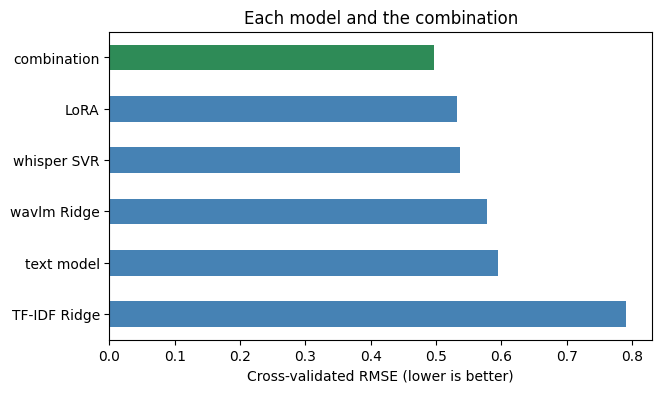

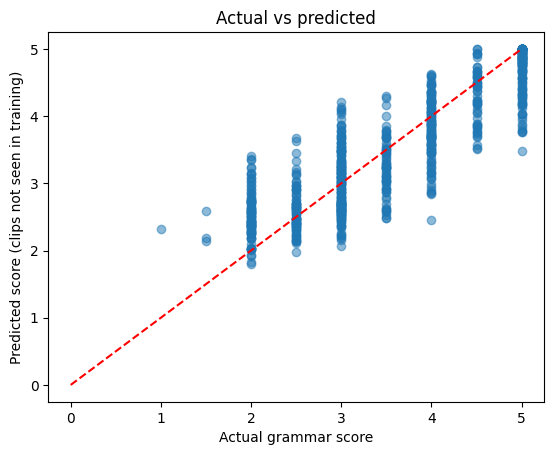

In [10]:
print(f"Training RMSE                                  : {rmse(y[keep], train_final[keep]):.4f}")
print(f"Cross-validated RMSE (clips not seen in training) : {rmse(y[keep], stack_oof[keep]):.4f}")
print(f"Cross-validated RMSE, weighted like the test set  : {wrmse(y, stack_oof):.4f}")
print(f"Baseline RMSE (always predict the mean)           : {rmse(y[keep], np.full(keep.sum(), y[keep].mean())):.4f}")
print(f"Cross-validated Pearson correlation               : {pearsonr(y[keep], stack_oof[keep])[0]:.4f}")

single = pd.Series({n: rmse(y[keep], np.clip(oof[n][keep], 0, 5)) for n in names}).sort_values(ascending=False)
single["combination"] = rmse(y[keep], stack_oof[keep])
single.plot.barh(figsize=(7, 4), color=["steelblue"] * len(names) + ["seagreen"])
plt.xlabel("Cross-validated RMSE (lower is better)"); plt.title("Each model and the combination")
plt.show()

plt.scatter(y[keep], stack_oof[keep], alpha=0.5)
plt.plot([0, 5], [0, 5], "r--")
plt.xlabel("Actual grammar score"); plt.ylabel("Predicted score (clips not seen in training)"); plt.title("Actual vs predicted")
plt.show()

In [11]:
submission = pd.DataFrame({"filename": test["filename"], "label": test_final})
submission.to_csv("submission.csv", index=False)
submission.describe()

,label
count,216.000000
mean,3.238604
std,0.839901
min,1.854309
25%,2.576797
50%,3.084796
75%,3.698444
max,5.000000
